> **Executed record of a Kaggle kernel.** The cells below are the cells that ran. Kaggle does not return the executed notebook, so the outputs were put back afterwards by `tools/attach_kaggle_outputs.py`: printed text comes from the kernel's log (each line assigned to the cell whose code prints it), and each table or figure comes from the CSV or PNG file that cell saved. Everything shown was produced by the run; the placement is a reconstruction. Kernel: `dr-s4e-e1-cb`.

> **Kaggle kernel `dr-s4e-e1-cb`.** Training: class-balanced MSE, seeds 42-44, and the Kaggle control mse_s42_k. Built by `experiments/06_imbalance_losses/kaggle/build_kernels.py` from `experiments/06_imbalance_losses/06_imbalance_losses.ipynb`; only the settings cell differs. Inputs: `dr-s4e-e0-quick`.

# Stage 4e: Focal Loss and Class-Balanced Ordinal Regression (post-test)
### The two training strategies from our Phase 1 plan that Stages 3 and 4 did not run

**Plan and predictions (written before any run):** [`experiments/06_imbalance_losses/hypothesis.md`](hypothesis.md). The test set was opened once in Stage 4c, so every test number here is **post-test**. These numbers are reported for comparison, drive no choice, and never replace the Stage 4c headline.

**What changes vs. Stage 4:** only the loss. Everything else (EfficientNet-B3, CLAHE + blur, 300 px, 60 epochs, batch 16, Adam lr 1e-4, augmentation, 10 snapshots, the Stage 3 split, seeds 42-44) is copied unchanged from [`experiments/02_ordinal_regression/02_ordinal_regression.ipynb`](../02_ordinal_regression/02_ordinal_regression.ipynb).

| Run | Loss | Arms |
|---|---|---|
| `focal_s42-44` | focal loss, γ = 2, no α | **E_vote** (majority vote, like A), **E_soft** (averaged probabilities, like A_soft), **E_tuned** (tuned cut-offs, like B) |
| `mse_cb_s42-44` | class-balanced MSE, w_c ∝ n_c^-1/2 (the Stage 3 weighted-CE weights) | **F_round** (rounding, like C), **F_tuned** (tuned cut-offs, like D) |
| `ce_s42_k`, `mse_s42_k` | Stage 4 `ce_s42` / `mse_s42` retrained on Kaggle | platform control |

The Stage 4 runs (arms A, A_soft, B, C, D) are **reused, not retrained**. They come from the Kaggle dataset `dr-stage4-outputs`. The notebook runs as a chain of Kaggle kernels built by [`experiments/06_imbalance_losses/kaggle/build_kernels.py`](kaggle/build_kernels.py). Each kernel trains its share (`TRAIN_RUNS`), and the last one only analyses (`ANALYSE`).

## 1. Setup and settings

In [1]:
import hashlib
import io
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, fields, replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm
try:
    from IPython.display import display
except ImportError:
    display = print

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Kaggle: results go to /kaggle/working (this kernel's output); inputs (datasets, earlier kernels) are under /kaggle/input.
ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    WORK_DIR, LOCAL_DIR, INPUT_DIR = Path("/kaggle/working/dr-grading"), Path("/tmp/dr"), Path("/kaggle/input")
else:                                                          # elsewhere: folders from environment variables
    WORK_DIR = Path(os.environ.get("DR_WORK_DIR", "dr-grading")).resolve()
    LOCAL_DIR = WORK_DIR
    INPUT_DIR = Path(os.environ.get("DR_INPUT_DIR", "dr-input")).resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
SESSION_START = time.time()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU")

device: cuda | Tesla T4


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


In [2]:
QUICK_TEST = False        # True = tiny runs (few epochs, few batches, separate output folder) to check every code path
TRAIN_RUNS = ['mse_cb_s42', 'mse_cb_s43', 'mse_cb_s44', 'mse_s42_k'] # names of the runs this kernel may train (None = all, [] = none)
ANALYSE = False           # tables, bootstrap, prediction check and post-hoc checks
SAVE_IMAGE_CACHE = False  # zip the downloaded images into this kernel's output for the next kernels
TIME_BUDGET_H = 11.0      # do not start a new run after this many hours (Kaggle stops a session at 12 h)
CHECKPOINT_EVERY = 1      # save a resumable checkpoint every N epochs
SPLIT_SEED = 42           # the train/val/test split is the same for every run (same as Stages 3 and 4)
FOCAL_GAMMA = 2.0         # focal loss focusing parameter (Lin et al. 2017); fixed in experiments/06_imbalance_losses/hypothesis.md


@dataclass
class Config:
    # The Stage 4 settings, unchanged (the Stage 3 baseline `2_aug_lr1e-4`).
    image_size: int = 300
    epochs: int = 60
    batch_size: int = 16
    lr: float = 1e-4
    weight_decay: float = 1e-4
    grad_clip: float = 0.1
    n_snapshots: int = 10
    seed: int = 42
    backbone: str = "efficientnet_b3"
    pretrained: bool = True
    use_amp: bool = True
    augment: bool = True
    loss: str = "ce"              # "ce" | "mse" (Stage 4) | "focal" | "mse_cb" (Stage 4e)
    dedupe: bool = False
    max_train_batches: int = 0


BASE_CFG = Config()
SEEDS = [42, 43, 44]
STAGE4E_DIR = WORK_DIR / "stage4e"
if QUICK_TEST:
    BASE_CFG = replace(BASE_CFG, epochs=4, n_snapshots=2, max_train_batches=5, image_size=224)
    SEEDS = [42]
    STAGE4E_DIR = WORK_DIR / "stage4e_quick_test"           # never mixed with the real runs
if device.type != "cuda" and not QUICK_TEST and TRAIN_RUNS != []:
    raise RuntimeError("Training needs a GPU: enable a T4 for this kernel (or set TRAIN_RUNS = [] to only analyse).")
if device.type != "cuda":
    BASE_CFG = replace(BASE_CFG, use_amp=False)
RUNS_DIR, FIG_DIR = STAGE4E_DIR / "runs", STAGE4E_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {}
for seed in SEEDS:
    for loss in ("focal", "mse_cb"):
        EXPERIMENTS[f"{loss}_s{seed}"] = replace(BASE_CFG, loss=loss, seed=seed)
EXPERIMENTS["ce_s42_k"] = replace(BASE_CFG, loss="ce", seed=42)       # platform control (Stage 4 ran on Colab)
EXPERIMENTS["mse_s42_k"] = replace(BASE_CFG, loss="mse", seed=42)

print(json.dumps(asdict(BASE_CFG), indent=2))
print("experiments:", ", ".join(EXPERIMENTS), "| this kernel trains:", "all" if TRAIN_RUNS is None else TRAIN_RUNS)

{
  "image_size": 300,
  "epochs": 60,
  "batch_size": 16,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "grad_clip": 0.1,
  "n_snapshots": 10,
  "seed": 42,
  "backbone": "efficientnet_b3",
  "pretrained": true,
  "use_amp": true,
  "augment": true,
  "loss": "ce",
  "dedupe": false,
  "max_train_batches": 0
}
experiments: focal_s42, mse_cb_s42, focal_s43, mse_cb_s43, focal_s44, mse_cb_s44, ce_s42_k, mse_s42_k | this kernel trains: ['mse_cb_s42', 'mse_cb_s43', 'mse_cb_s44', 'mse_s42_k']


### Inputs from earlier kernels and datasets

* **Stage 4 runs** (`ce_s42-44`, `mse_s42-44`: config and `outputs.npz`), read in place from `dr-stage4-outputs`.
* **Finished Stage 4e runs** from earlier kernels, copied in so the chain continues where it stopped. An interrupted run is copied with its checkpoint and resumes.
* **Image cache** (`aptos512.zip`) from the quick-test kernel, so later kernels do not download the images again.
* **`mse_s42` weights** from `dr-stage4-weights`, for the Grad-CAM check.

In [3]:
def find_inputs(pattern):
    return sorted(INPUT_DIR.glob(pattern)) if INPUT_DIR.exists() else []


STAGE4_NAMES = [f"{loss}_s{seed}" for seed in (42, 43, 44) for loss in ("ce", "mse")]
STAGE4_RUNS = {}
for f in find_inputs("**/stage4/runs/*/outputs.npz"):
    if f.parent.name in STAGE4_NAMES:
        STAGE4_RUNS.setdefault(f.parent.name, f.parent)
print("Stage 4 runs found:", sorted(STAGE4_RUNS))

for cfg_file in find_inputs(f"**/dr-grading/{STAGE4E_DIR.name}/runs/*/config.json"):
    src, dst = cfg_file.parent, RUNS_DIR / cfg_file.parent.name
    if (dst / "results.json").exists():
        continue
    if (src / "results.json").exists():                   # finished: copy without weights or checkpoint
        shutil.rmtree(dst, ignore_errors=True)
        shutil.copytree(src, dst, ignore=shutil.ignore_patterns("*.pt", "*.tmp"))
    elif not dst.exists():                                 # interrupted: copy with its checkpoint, it resumes
        shutil.copytree(src, dst, ignore=shutil.ignore_patterns("*.tmp"))
print("Stage 4e runs restored:", sorted(p.parent.name for p in RUNS_DIR.glob("*/results.json")))

IMAGE_CACHES = find_inputs("**/aptos512.zip")
_weights = find_inputs("**/mse_s42_best_val_weights.pt")
GRADCAM_WEIGHTS = _weights[0] if _weights else None
print("image cache:", IMAGE_CACHES[0] if IMAGE_CACHES else "none (will download)", "| Grad-CAM weights:", GRADCAM_WEIGHTS)

Stage 4 runs found: []
Stage 4e runs restored: []
image cache: /kaggle/input/notebooks/subhammahapatra004/dr-s4e-e0-quick/dr-grading/aptos512.zip | Grad-CAM weights: None


## 2. Data (unchanged from Stage 4)

APTOS 2019 from the Hugging Face mirror [`sngsfydy/aptos`](https://huggingface.co/datasets/sngsfydy/aptos), shrunk to 512 px. The image order comes from the same `labels.csv`, so the split is **identical to Stages 3 and 4**. Section 6 asserts this against the saved Stage 4 outputs.

In [4]:
HF_REPO = "sngsfydy/aptos"
IMG_DIR = LOCAL_DIR / "aptos512"
CACHE_ZIP = WORK_DIR / "aptos512.zip"
MAX_SIDE = 512


def list_shards():
    with urllib.request.urlopen(f"https://huggingface.co/api/datasets/{HF_REPO}/tree/main/data") as r:
        return sorted(f["path"] for f in json.load(r) if f["path"].endswith(".parquet"))


def convert_shard(parquet_path, out_dir):
    # Save every image in one parquet shard as a <hash>.jpg (<= 512 px). Returns [(file name, grade), ...].
    rows = []
    pf = pq.ParquetFile(parquet_path)
    for group in range(pf.num_row_groups):
        table = pf.read_row_group(group).to_pydict()
        for img, label in zip(table["image"], table["label"]):
            raw = img["bytes"]
            name = hashlib.sha1(raw).hexdigest()[:16] + ".jpg"     # identical photos get identical names
            im = Image.open(io.BytesIO(raw)).convert("RGB")
            scale = MAX_SIDE / max(im.size)
            im.resize((round(im.width * scale), round(im.height * scale)), Image.LANCZOS).save(out_dir / name, quality=95)
            rows.append((name, int(label)))
    return rows


def download_aptos(out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for shard in list_shards():
        local = LOCAL_DIR / Path(shard).name
        print("downloading", local.name, flush=True)
        subprocess.run(["curl", "-sSL", "--retry", "5", "-o", str(local),
                        f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{shard}"], check=True)
        rows += convert_shard(local, out_dir)
        local.unlink()                                             # free the disk before the next shard
        print(f"  {len(rows)} images so far", flush=True)
    pd.DataFrame(rows, columns=["id_code", "label"]).to_csv(out_dir / "labels.csv", index=False)



if not (IMG_DIR / "labels.csv").exists():
    if IMAGE_CACHES:                                               # an earlier kernel did the download
        print("restoring cached images from", IMAGE_CACHES[0])
        shutil.unpack_archive(IMAGE_CACHES[0], IMG_DIR)
    else:
        download_aptos(IMG_DIR)
        if SAVE_IMAGE_CACHE:
            print("saving an image cache for the next kernels ...")
            shutil.make_archive(str(CACHE_ZIP.with_suffix("")), "zip", IMG_DIR)

df = pd.read_csv(IMG_DIR / "labels.csv")
df["path"] = df["id_code"].map(lambda name: IMG_DIR / name)
labels = df["label"].to_numpy()
print(f"{len(df)} images, {df['id_code'].nunique()} distinct files")

restoring cached images from /kaggle/input/notebooks/subhammahapatra004/dr-s4e-e0-quick/dr-grading/aptos512.zip
3662 images, 3534 distinct files


In [5]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


with ThreadPoolExecutor(os.cpu_count()) as pool:
    df["hash"] = list(tqdm(pool.map(file_hash, df["path"]), total=len(df), desc="hashing"))

groups = df.groupby("hash")["label"].agg(["size", "nunique"])
conflict_hashes = set(groups.index[groups["nunique"] > 1])
df["conflicting_duplicate"] = df["hash"].isin(conflict_hashes)
print(f"{int((groups['size'] > 1).sum())} groups of identical images, {len(conflict_hashes)} of them with conflicting grades")


def make_split(positions, seed=SPLIT_SEED, val_frac=0.15, test_frac=0.15):
    # Stratified train/val/test row positions (into df). With all positions this is exactly the Stage 3 split.
    train_val, test = train_test_split(positions, test_size=test_frac, stratify=labels[positions], random_state=seed)
    train, val = train_test_split(train_val, test_size=val_frac / (1 - test_frac),
                                  stratify=labels[train_val], random_state=seed)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


keep = ~df["conflicting_duplicate"] & ~df.duplicated("hash")      # de-duplicated data set
SPLITS = {False: make_split(np.arange(len(df))), True: make_split(np.flatnonzero(keep.to_numpy()))}

for dedupe, split in SPLITS.items():
    train_hashes = set(df["hash"].to_numpy()[split["train"]])
    leaked = sum(h in train_hashes for h in df["hash"].to_numpy()[split["test"]])
    print(f"\n{'de-duplicated' if dedupe else 'all images (Stage 3 split)'}: {sum(map(len, split.values()))} images, "
          f"{leaked} test images with a twin in training")
    print(pd.DataFrame({name: np.bincount(labels[idx], minlength=NUM_CLASSES) for name, idx in split.items()},
                       index=CLASS_NAMES).T.to_string())

123 groups of identical images, 30 of them with conflicting grades

all images (Stage 3 split): 3662 images, 29 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1263   258       699     135  207
val      271    56       150      29   44
test     271    56       150      29   44

de-duplicated: 3504 images, 0 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1257   236       646     124  189
val      269    51       138      27   41
test     270    51       138      26   41
(3662, 300, 300, 3), 0.99 GB, 16s



## 3. Pre-processing (unchanged)

CLAHE on the LAB lightness channel (clip 2.0, 8x8 tiles), 5x5 Gaussian blur, square resize.

In [ ]:
def preprocess(path, size):
    # Load -> shrink to <= 512 px -> CLAHE + blur -> square resize. Returns RGB uint8 (size, size, 3).
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    h, w = bgr.shape[:2]
    if max(h, w) > 512:
        scale = 512 / max(h, w)
        bgr = cv2.resize(bgr, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    bgr = cv2.GaussianBlur(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), (5, 5), 0)
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


paths = df["path"].tolist()
images = np.empty((len(paths), BASE_CFG.image_size, BASE_CFG.image_size, 3), dtype=np.uint8)


def fill(i):
    images[i] = preprocess(paths[i], BASE_CFG.image_size)


t0 = time.time()
with ThreadPoolExecutor(os.cpu_count()) as pool:            # OpenCV releases the GIL, so threads are enough
    list(tqdm(pool.map(fill, range(len(paths))), total=len(paths), desc="pre-processing"))
print(f"{images.shape}, {images.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s")

## 4. Model, metrics and the two new losses

The model and metrics are copied from Stage 4. Focal loss uses the 5-output head, like `ce`. Class-balanced MSE uses the 1-output head, like `mse`.

* **Focal loss** (Lin et al. 2017): −(1 − p_t)^γ · log p_t with γ = 2 and no α. Confidently right images (mostly No DR) contribute almost nothing, so training focuses on the hard ones. α class-weighting is a separate axis, and weighted CE was already tested in Stage 3.
* **Class-balanced MSE:** w_c · (output − grade)², with w_c ∝ n_c^−1/2 scaled so the mean weight over the training images is 1. These are exactly the Stage 3 weighted-CE weights.

In [ ]:
def n_outputs(cfg):
    return 1 if cfg.loss in ("mse", "mse_cb") else NUM_CLASSES


class DRNet(nn.Module):
    def __init__(self, backbone="efficientnet_b3", pretrained=True, outputs=NUM_CLASSES):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, global_pool="avg")
        self.head = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512), nn.Dropout(0.5), nn.ReLU(inplace=True),
            nn.Linear(512, 512), nn.Dropout(0.25), nn.ReLU(inplace=True),
            nn.Linear(512, outputs),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


_mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
_std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
_black = -_mean / _std     # what a black pixel looks like after normalisation


def to_model_input(batch_uint8):
    # numpy (B, H, W, 3) uint8 -> normalised float tensor (B, 3, H, W) on the GPU.
    x = torch.from_numpy(batch_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)


def augment_batch(x):
    # Random horizontal flip + random rotation (0-360 degrees), as in Stage 3. Empty corners stay black.
    n = x.shape[0]
    x = x - _black
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    angle = torch.rand(n, device=x.device) * 2 * math.pi
    cos, sin, zero = angle.cos(), angle.sin(), torch.zeros_like(angle)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)    # (n, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return (x + _black).contiguous(memory_format=torch.channels_last)

In [ ]:
ROUNDING = np.array([0.5, 1.5, 2.5, 3.5])


def qwk(y, pred, k=NUM_CLASSES):
    # Quadratic weighted kappa from the confusion matrix (same value as sklearn's cohen_kappa_score, much faster).
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k).astype(float)
    weights = np.subtract.outer(np.arange(k), np.arange(k)) ** 2 / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / cm.sum()
    denom = (weights * expected).sum()
    return float(1 - (weights * cm).sum() / denom) if denom > 0 else 0.0


def severity_score(out):
    # (..., 5) probabilities -> expected grade; (..., 1) regression output -> that number.
    return out @ np.arange(NUM_CLASSES) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def at_least_score(out, k):
    # Score for "grade >= k": P(grade >= k) for ce, the regression output for mse (any monotone score works for AUC).
    return out[..., k:].sum(-1) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def apply_cutoffs(score, cutoffs):
    return np.digitize(score, cutoffs).astype(int)


def fit_cutoffs(score, y, step=0.01, passes=3):
    # Coordinate search: move one cut-off at a time to the grid value with the best QWK, keeping them ordered.
    cutoffs = ROUNDING.copy()
    best = qwk(y, apply_cutoffs(score, cutoffs))
    for _ in range(passes):
        for i in range(len(cutoffs)):
            lo = cutoffs[i - 1] + step if i > 0 else -0.5
            hi = cutoffs[i + 1] - step if i < len(cutoffs) - 1 else NUM_CLASSES - 0.5
            for value in np.arange(lo, hi + 1e-9, step):
                trial = cutoffs.copy()
                trial[i] = value
                score_trial = qwk(y, apply_cutoffs(score, trial))
                if score_trial > best:                       # strictly better: ties keep the current cut-off
                    best, cutoffs = score_trial, trial
    return cutoffs


def majority_vote(snapshot_probs):
    # snapshot_probs: (n_snapshots, n_images, 5) -> one predicted grade per image (paper's ensemble rule).
    votes = snapshot_probs.argmax(-1)
    tally = np.stack([(votes == c).sum(0) for c in range(NUM_CLASSES)], 1).astype(float)
    tally += 1e-3 * snapshot_probs.mean(0)                   # tie-break
    return tally.argmax(1)


def safe_auc(y_binary, score):
    return float(roc_auc_score(y_binary, score)) if 0 < y_binary.sum() < len(y_binary) else float("nan")


def compute_metrics(y, pred, out):
    _, rec, _, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    ref_true, ref_pred = y >= 2, pred >= 2
    return {
        "qwk": qwk(y, pred),
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        **{f"recall_{name}": float(rec[c]) for c, name in enumerate(CLASS_NAMES)},
        "off_by_2_or_more": int(np.sum(np.abs(y - pred) >= 2)),
        "ref_sensitivity": float((ref_pred & ref_true).sum() / max(ref_true.sum(), 1)),
        "ref_specificity": float((~ref_pred & ~ref_true).sum() / max((~ref_true).sum(), 1)),
        "ref_auc": safe_auc(ref_true, at_least_score(out, 2)),
        "ordinal_auc": float(np.nanmean([safe_auc(y >= k, at_least_score(out, k)) for k in range(1, NUM_CLASSES)])),
        "confusion_matrix": confusion_matrix(y, pred, labels=list(range(NUM_CLASSES))).tolist(),
    }

## 5. Training (same loop as Stage 4)

The best epoch is chosen on validation QWK with the model's default rule (arg-max for 5 outputs, rounding for 1). Validation and test outputs are kept for the best epoch and the 10 snapshots. A checkpoint is written after every epoch, and a re-run resumes. **Time guard:** no new run starts after `TIME_BUDGET_H`. Push the kernel again with its own output as an input to continue.

In [ ]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def class_weights(cfg):
    # The Stage 3 weighted-CE weights: w_c ~ 1/sqrt(n_c), scaled so the mean weight over the training images is 1.
    counts = np.bincount(labels[SPLITS[cfg.dedupe]["train"]], minlength=NUM_CLASSES).astype(float)
    w = counts ** -0.5
    return w / (w * counts).sum() * counts.sum()


def make_criterion(cfg):
    if cfg.loss == "ce":
        return nn.CrossEntropyLoss()
    if cfg.loss == "mse":                           # ordinal regression: squared distance to the true grade
        return lambda out, y: F.mse_loss(out[:, 0], y.float())
    if cfg.loss == "focal":                         # Lin et al. 2017: -(1 - p_t)^gamma * log p_t, no alpha
        def focal(out, y):
            log_pt = F.log_softmax(out, dim=1).gather(1, y[:, None])[:, 0]
            return (-((1.0 - log_pt.exp()) ** FOCAL_GAMMA) * log_pt).mean()
        return focal
    if cfg.loss == "mse_cb":                        # class-balanced ordinal regression
        w = class_weights(cfg)
        print("  class weights:", {name: round(float(x), 2) for name, x in zip(CLASS_NAMES, w)})
        w = torch.tensor(w, dtype=torch.float32, device=device)
        return lambda out, y: (w[y] * (out[:, 0] - y.float()) ** 2).mean()
    raise ValueError(f"unknown loss {cfg.loss!r}")


def default_grades(out):
    # The rule used to pick the best epoch: arg-max for ce/focal, rounding for mse/mse_cb.
    return out.argmax(1) if out.shape[1] == NUM_CLASSES else apply_cutoffs(out[:, 0], ROUNDING)


@torch.no_grad()
def predict(model, indices, cfg, batch_size=32):
    # Softmax probabilities (n, 5) for ce/focal, the raw regression output (n, 1) for mse/mse_cb.
    model.eval()
    out = []
    for start in range(0, len(indices), batch_size):
        x = to_model_input(images[indices[start:start + batch_size]])
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            logits = model(x).float()
        out.append((torch.softmax(logits, dim=1) if n_outputs(cfg) == NUM_CLASSES else logits).cpu())
    return torch.cat(out).numpy()


def train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng):
    model.train()
    order = rng.permutation(split["train"])
    n_batches = len(order) // cfg.batch_size                                   # drop the last partial batch
    if cfg.max_train_batches:
        n_batches = min(n_batches, cfg.max_train_batches)
    total_loss, seen = 0.0, 0
    progress = tqdm(range(n_batches), desc="  training", leave=False)
    for b in progress:
        idx = np.sort(order[b * cfg.batch_size:(b + 1) * cfg.batch_size])      # sorted = faster memory reads
        x = to_model_input(images[idx])
        if cfg.augment:
            x = augment_batch(x)
        y = torch.from_numpy(labels[idx]).to(device)

        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            out = model(x)
        loss = criterion(out.float(), y)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                             # so clipping sees real gradient sizes
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(y)
        seen += len(y)
        progress.set_postfix(loss=f"{total_loss / seen:.3f}")
    return total_loss / seen

In [ ]:
def save_atomically(path, obj):
    # Write to a temp file, then rename: a crash mid-save can never leave a broken file behind.
    tmp = path.with_suffix(".tmp")
    try:
        torch.save(obj, tmp)
        tmp.replace(path)
    except (RuntimeError, OSError) as err:
        tmp.unlink(missing_ok=True)
        print(f"  warning: could not save {path.name} ({err})")


def load_run(run_dir, cfg):
    saved = np.load(run_dir / "outputs.npz")
    return {"config": cfg, "log": pd.read_csv(run_dir / "log.csv"), **{k: saved[k] for k in saved.files}}


def run_experiment(name, cfg):
    # Train one configuration and save its validation/test outputs. Resumes if interrupted.
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    config_file, done_file = run_dir / "config.json", run_dir / "results.json"
    ckpt_path, best_path = run_dir / "last.pt", run_dir / "best_val_weights.pt"

    saved_cfg = json.loads(config_file.read_text()) if config_file.exists() else None
    if saved_cfg is not None:
        saved_cfg = {**{f.name: f.default for f in fields(Config)}, **saved_cfg}
    if saved_cfg is not None and saved_cfg != asdict(cfg) and done_file.exists():
        # Never throw away a finished run because a setting differs (e.g. a CPU runtime turns AMP off).
        changed = {k: (saved_cfg.get(k), v) for k, v in asdict(cfg).items() if saved_cfg.get(k) != v}
        raise RuntimeError(f"{name} already finished with other settings {changed} (saved, now). "
                           f"Delete {run_dir} by hand if you really want to retrain it.")
    if saved_cfg != asdict(cfg):              # a new experiment, or an unfinished one whose settings changed
        ckpt_path.unlink(missing_ok=True)
        done_file.unlink(missing_ok=True)
        config_file.write_text(json.dumps(asdict(cfg), indent=2))
    if done_file.exists():                    # finished in an earlier session
        print(f"=== {name} === already finished, loading saved outputs")
        return load_run(run_dir, cfg)

    if time.time() - SESSION_START > TIME_BUDGET_H * 3600:
        print(f"time guard: not starting {name} ({TIME_BUDGET_H} h used); push this kernel again "
              "with its own output as an input to continue")
        return None
    split = SPLITS[cfg.dedupe]
    print(f"\n=== {name} ===  loss={cfg.loss}  seed={cfg.seed}  dedupe={cfg.dedupe}  lr={cfg.lr}  epochs={cfg.epochs}")
    seed_everything(cfg.seed)
    model = DRNet(cfg.backbone, cfg.pretrained, n_outputs(cfg)).to(device).to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
    criterion = make_criterion(cfg)
    rng = np.random.default_rng(cfg.seed)

    snapshot_epochs = {round(cfg.epochs * k / cfg.n_snapshots) for k in range(1, cfg.n_snapshots + 1)}
    progress = {"log": [], "snap_val": [], "snap_test": [], "best_val_qwk": -2.0, "best_epoch": 0,
                "best_val": None, "best_test": None}
    first_epoch = 1

    if ckpt_path.exists():                                                     # continue an interrupted run
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except Exception as err:
            ckpt = None
            print(f"  could not read {ckpt_path.name} ({err}); starting from scratch")
        if ckpt is not None:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            rng.bit_generator.state = ckpt["rng_numpy"]
            torch.set_rng_state(ckpt["rng_torch"])
            if ckpt["rng_cuda"] is not None:
                torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
            progress, first_epoch = ckpt["progress"], ckpt["epoch"] + 1
            print(f"  RESUMED after epoch {ckpt['epoch']} (best so far: val QWK {progress['best_val_qwk']:.3f})")

    y_val = labels[split["val"]]
    started, epochs_done_now = time.time(), 0
    for epoch in range(first_epoch, cfg.epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng)

        val_out = predict(model, split["val"], cfg)
        val_pred = default_grades(val_out)
        val_qwk, val_acc = qwk(y_val, val_pred), float(accuracy_score(y_val, val_pred))
        progress["log"].append({"epoch": epoch, "train_loss": train_loss, "val_qwk": val_qwk, "val_acc": val_acc})

        notes, test_out = "", None
        if val_qwk > progress["best_val_qwk"]:                                 # new best on validation
            test_out = predict(model, split["test"], cfg)
            progress.update(best_val_qwk=val_qwk, best_epoch=epoch, best_val=val_out, best_test=test_out)
            save_atomically(best_path, model.state_dict())
            notes += " NEW BEST"
        if epoch in snapshot_epochs:                                           # ensemble member
            progress["snap_val"].append(val_out)
            progress["snap_test"].append(test_out if test_out is not None else predict(model, split["test"], cfg))
            notes += f" snapshot {len(progress['snap_test'])}/{cfg.n_snapshots}"

        pd.DataFrame(progress["log"]).to_csv(run_dir / "log.csv", index=False)    # live log, readable at any time
        if epoch % CHECKPOINT_EVERY == 0 and epoch < cfg.epochs:
            save_atomically(ckpt_path, {
                "epoch": epoch, "progress": progress, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "rng_numpy": rng.bit_generator.state, "rng_torch": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None})

        epochs_done_now += 1
        eta_min = (time.time() - started) / epochs_done_now * (cfg.epochs - epoch) / 60
        print(f"[{name}] epoch {epoch:2d}/{cfg.epochs} | loss {train_loss:.3f} | val QWK {val_qwk:.3f} "
              f"(best {progress['best_val_qwk']:.3f} @ep{progress['best_epoch']}) | val acc {val_acc:.3f} | "
              f"{time.time() - t0:.0f}s | ~{eta_min:.0f} min left |{notes}")

    np.savez_compressed(run_dir / "outputs.npz", y_val=y_val, y_test=labels[split["test"]],
                        val_idx=split["val"], test_idx=split["test"],
                        best_val=progress["best_val"], best_test=progress["best_test"],
                        snap_val=np.stack(progress["snap_val"]), snap_test=np.stack(progress["snap_test"]))
    done_file.write_text(json.dumps({"best_epoch": progress["best_epoch"],              # written last = run complete
                                     "best_val_qwk": progress["best_val_qwk"]}, indent=2))
    ckpt_path.unlink(missing_ok=True)
    return load_run(run_dir, cfg)

In [6]:
def config_from(run_dir):
    saved = json.loads((run_dir / "config.json").read_text())
    names = {f.name for f in fields(Config)}
    return Config(**{k: v for k, v in saved.items() if k in names})


runs = {}
for name, cfg in EXPERIMENTS.items():
    run_dir = RUNS_DIR / name
    if (run_dir / "results.json").exists():                # finished in an earlier kernel: load as saved
        runs[name] = load_run(run_dir, config_from(run_dir))
        print(f"=== {name} === finished earlier, loaded")
    elif TRAIN_RUNS is None or name in TRAIN_RUNS:
        result = run_experiment(name, cfg)
        if result is not None:
            runs[name] = result
print("finished Stage 4e runs:", sorted(runs))

=== mse_cb_s42 ===  loss=mse_cb  seed=42  dedupe=False  lr=0.0001  epochs=60
  class weights: {'No DR': 0.69, 'Mild': 1.53, 'Moderate': 0.93, 'Severe': 2.12, 'PDR': 1.71}
[mse_cb_s42] epoch  1/60 | loss 1.164 | val QWK 0.822 (best 0.822 @ep1) | val acc 0.715 | 57s | ~56 min left | NEW BEST
[mse_cb_s42] epoch  2/60 | loss 0.624 | val QWK 0.866 (best 0.866 @ep2) | val acc 0.767 | 24s | ~39 min left | NEW BEST
[mse_cb_s42] epoch  3/60 | loss 0.552 | val QWK 0.873 (best 0.873 @ep3) | val acc 0.756 | 24s | ~33 min left | NEW BEST
[mse_cb_s42] epoch  4/60 | loss 0.468 | val QWK 0.874 (best 0.874 @ep4) | val acc 0.755 | 25s | ~30 min left | NEW BEST
[mse_cb_s42] epoch  5/60 | loss 0.485 | val QWK 0.854 (best 0.874 @ep4) | val acc 0.742 | 24s | ~28 min left |
[mse_cb_s42] epoch  6/60 | loss 0.421 | val QWK 0.815 (best 0.874 @ep4) | val acc 0.733 | 26s | ~27 min left | snapshot 1/10
[mse_cb_s42] epoch  7/60 | loss 0.382 | val QWK 0.864 (best 0.874 @ep4) | val acc 0.756 | 24s | ~26 min left |
[m


/usr/local/lib/python3.13/dist-packages/mistune.py:435: SyntaxWarning: invalid escape sequence '\|'
  cells[i][c] = re.sub('\\\\\|', '|', cell)
/usr/local/lib/python3.13/dist-packages/nbconvert/filters/filter_links.py:36: SyntaxWarning: invalid escape sequence '\_'
  text = re.sub(r'_', '\_', text) # Escape underscores in display text
[NbConvertApp] Converting notebook __notebook__.ipynb to notebook
[NbConvertApp] Writing 2967122 bytes to __notebook__.ipynb
[NbConvertApp] Converting notebook __notebook__.ipynb to html
[NbConvertApp] Writing 2889110 bytes to __results__.html


## 6. Results: every arm, every seed (post-test)

The Stage 4 runs are loaded from `dr-stage4-outputs` and decoded with the same rules as in Stage 4. Their numbers must match `experiments/02_ordinal_regression/results/results_per_seed.csv`. One row per (group, seed, mode, arm). Group *main* holds the Colab Stage 4 runs and the Kaggle Stage 4e runs. Group *control* holds the Kaggle retrains of `ce_s42` / `mse_s42`.

| Arm | Loss | Rule |
|---|---|---|
| A / A_soft / B | CE (Stage 4) | vote / averaged arg-max / tuned cut-offs |
| C / D | MSE (Stage 4) | rounding / tuned cut-offs |
| E_vote / E_soft / E_tuned | focal | vote / averaged arg-max / tuned cut-offs |
| F_round / F_tuned | class-balanced MSE | rounding / tuned cut-offs |

In [ ]:
ARM_NAMES = {"ce": ("A", "B"), "mse": ("C", "D"), "focal": ("E_vote", "E_tuned"), "mse_cb": ("F_round", "F_tuned")}
SOFT_NAME = {"ce": "A_soft", "focal": "E_soft"}
ARM_ORDER = ["A", "A_soft", "B", "E_vote", "E_soft", "E_tuned", "C", "D", "F_round", "F_tuned"]


def load_stage4_run(run_dir):
    return {"config": config_from(run_dir), **dict(np.load(run_dir / "outputs.npz"))}


def decide(run, mode):
    # Grades for the test set from one finished run, for all of its arms. Cut-offs come from validation only.
    cfg = run["config"]
    if mode == "single":
        val_out, test_out = run["best_val"], run["best_test"]
    else:
        val_out, test_out = run["snap_val"].mean(0), run["snap_test"].mean(0)
    default_arm, tuned_arm = ARM_NAMES[cfg.loss]
    if test_out.shape[-1] == NUM_CLASSES:
        default = test_out.argmax(1) if mode == "single" else majority_vote(run["snap_test"])
    else:
        default = apply_cutoffs(severity_score(test_out), ROUNDING)
    cutoffs = fit_cutoffs(severity_score(val_out), run["y_val"])
    arms = {default_arm: (default, test_out, None),
            tuned_arm: (apply_cutoffs(severity_score(test_out), cutoffs), test_out, cutoffs)}
    if mode == "ensemble" and cfg.loss in SOFT_NAME:
        arms[SOFT_NAME[cfg.loss]] = (test_out.argmax(1), test_out, None)
    return arms


def pooled_bootstrap(triples, n_boot=2000, seed=0):
    # triples: one (y, pred_old, pred_new) per training seed, all on the same test images -> 95% CI of the mean ΔQWK.
    y0 = triples[0][0]
    assert all(np.array_equal(y, y0) for y, _, _ in triples), "the seeds must share the test images"
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y0), len(y0))
        diffs[i] = np.mean([qwk(y[idx], new[idx]) - qwk(y[idx], old[idx]) for y, old, new in triples])
    return np.percentile(diffs, [2.5, 97.5])


def collect_runs():
    out = [("main", int(name.split("_s")[1]), f"stage4/{name}", load_stage4_run(d)) for name, d in STAGE4_RUNS.items()]
    out += [("control" if name.endswith("_k") else "main", run["config"].seed, f"stage4e/{name}", run)
            for name, run in runs.items()]
    test_idx = SPLITS[False]["test"]
    for _, _, name, run in out:                              # every run must use the Stage 3 split
        assert np.array_equal(run["test_idx"], test_idx) and np.array_equal(run["y_test"], labels[test_idx]), \
            f"{name}: the test split differs from Stage 3/4"
    return out

In [7]:
if ANALYSE:
    STAGE4E_DIR.mkdir(parents=True, exist_ok=True)
    all_runs = collect_runs()
    rows, decisions, cutoff_log = [], {}, {}
    for group, seed, name, run in all_runs:
        for mode in ("single", "ensemble"):
            for arm, (pred, out, cutoffs) in decide(run, mode).items():
                y = run["y_test"]
                decisions[(group, seed, mode, arm)] = (y, pred)
                if cutoffs is not None:
                    cutoff_log[f"{group} seed={seed} {mode} {arm}"] = [round(float(c), 2) for c in cutoffs]
                m = compute_metrics(y, pred, out)
                rows.append({"group": group, "seed": seed, "mode": mode, "arm": arm, "run": name,
                             **{k: v for k, v in m.items() if k != "confusion_matrix"}})
    results = pd.DataFrame(rows).sort_values(["group", "seed", "mode", "arm"]).reset_index(drop=True)
    results.to_csv(STAGE4E_DIR / "results_per_seed.csv", index=False)
    (STAGE4E_DIR / "cutoffs.json").write_text(json.dumps(cutoff_log, indent=2))

    SHOW = ["qwk", "accuracy", "macro_f1", "recall_Mild", "recall_Moderate", "recall_Severe", "recall_PDR",
            "off_by_2_or_more", "ref_sensitivity", "ref_specificity", "ref_auc"]
    main = results[results["group"] == "main"]
    agg = main.groupby(["mode", "arm"])[SHOW].agg(["mean", "std"])
    summary = pd.DataFrame({col: agg[(col, "mean")].map("{:.3f}".format) + " ± " + agg[(col, "std")].fillna(0).map("{:.3f}".format)
                            for col in SHOW})
    summary["n_seeds"] = main.groupby(["mode", "arm"])["seed"].nunique()
    order = [(m, a) for m in ("ensemble", "single") for a in ARM_ORDER if (m, a) in summary.index]
    summary = summary.loc[order]
    summary.to_csv(STAGE4E_DIR / "results_mean_over_seeds.csv")
    print("Main split, mean ± std over seeds (post-test):")
    display(summary)

results_mean_over_seeds.csv
    mode     arm           qwk      accuracy      macro_f1   recall_Mild recall_Moderate recall_Severe    recall_PDR off_by_2_or_more ref_sensitivity ref_specificity       ref_auc  n_seeds
ensemble       A 0.897 ± 0.004 0.828 ± 0.004 0.647 ± 0.020 0.351 ± 0.088   0.900 ± 0.029 0.276 ± 0.034 0.606 ± 0.013   21.667 ± 0.577   0.946 ± 0.008   0.904 ± 0.016 0.979 ± 0.001        3
ensemble  A_soft 0.899 ± 0.001 0.828 ± 0.002 0.645 ± 0.012 0.357 ± 0.078   0.904 ± 0.032 0.253 ± 0.020 0.606 ± 0.013   21.333 ± 0.577   0.949 ± 0.013   0.904 ± 0.016 0.979 ± 0.001        3
ensemble       B 0.907 ± 0.007 0.776 ± 0.031 0.594 ± 0.028 0.238 ± 0.021   0.747 ± 0.116 0.437 ± 0.020 0.568 ± 0.023   15.667 ± 0.577   0.982 ± 0.012   0.879 ± 0.006 0.979 ± 0.001        3
ensemble  E_vote 0.901 ± 0.004 0.831 ± 0.007 0.647 ± 0.013 0.387 ± 0.021   0.904 ± 0.034 0.241 ± 0.069 0.583 ± 0.013   21.000 ± 1.000   0.945 ± 0.016   0.914 ± 0.003 0.985 ± 0.001        3
ensemble  E_soft 0.903 ± 0.

results_per_seed.csv (first 60 of 63 rows)
  group  seed     mode     arm                run      qwk  accuracy  macro_f1  recall_No DR  recall_Mild  recall_Moderate  recall_Severe  recall_PDR  off_by_2_or_more  ref_sensitivity  ref_specificity  ref_auc  ordinal_auc
control    42 ensemble       A   stage4e/ce_s42_k 0.908330  0.841818  0.666113       0.98893     0.375000         0.926667       0.275862    0.613636                20         0.964126         0.914373 0.975000     0.964878
control    42 ensemble  A_soft   stage4e/ce_s42_k 0.904678  0.838182  0.657405       0.99262     0.375000         0.920000       0.275862    0.568182                21         0.959641         0.917431 0.975000     0.964878
control    42 ensemble       B   stage4e/ce_s42_k 0.916023  0.798182  0.626686       0.97417     0.285714         0.793333       0.517241    0.568182                15         0.991031         0.892966 0.975000     0.964878
control    42 ensemble       C  stage4e/mse_s42_k 0.897898  0

### Paired bootstrap

Both arms of a contrast are scored on the same 550 test images. Resampling those images 2,000 times gives a 95% interval for the difference. *Pooled* averages ΔQWK over the seeds inside each resample. This covers test-set noise only.

In [8]:
CONTRASTS = [("ensemble", "E_vote", "A"), ("ensemble", "E_soft", "A_soft"), ("ensemble", "E_tuned", "B"),
             ("ensemble", "D", "E_tuned"), ("ensemble", "F_tuned", "D"), ("ensemble", "F_round", "C"),
             ("ensemble", "F_tuned", "A"), ("ensemble", "D", "A_soft"),
             ("single", "E_vote", "A"), ("single", "E_tuned", "B"), ("single", "F_tuned", "D"), ("single", "F_round", "C")]
if ANALYSE:
    boot_rows = []
    for mode, new, old in CONTRASTS:
        seeds = sorted(s for (g, s, m, a) in decisions if g == "main" and m == mode and a == new
                       and ("main", s, mode, old) in decisions)
        triples = {s: (decisions[("main", s, mode, old)][0], decisions[("main", s, mode, old)][1],
                       decisions[("main", s, mode, new)][1]) for s in seeds}
        groups = [(str(s), [t]) for s, t in triples.items()] + ([(f"pooled ({len(seeds)})", list(triples.values()))] if seeds else [])
        for label, ts in groups:
            lo, hi = pooled_bootstrap(ts)
            delta = float(np.mean([qwk(y, n) - qwk(y, o) for y, o, n in ts]))
            boot_rows.append({"mode": mode, "contrast": f"{new} - {old}", "seed": label, "delta_qwk": delta,
                              "ci_low": lo, "ci_high": hi, "excludes_0": bool(lo > 0 or hi < 0)})
    bootstrap = pd.DataFrame(boot_rows)
    bootstrap.to_csv(STAGE4E_DIR / "paired_bootstrap.csv", index=False)
    display(bootstrap.style.format(precision=3).hide(axis="index"))

paired_bootstrap.csv
    mode        contrast       seed  delta_qwk    ci_low   ci_high  excludes_0
ensemble      E_vote - A         42  -0.001323 -0.009103  0.006816       False
ensemble      E_vote - A         43   0.008387 -0.004317  0.023259       False
ensemble      E_vote - A         44   0.003765 -0.009240  0.018436       False
ensemble      E_vote - A pooled (3)   0.003610 -0.003302  0.011460       False
ensemble E_soft - A_soft         42   0.003682 -0.005810  0.015147       False
ensemble E_soft - A_soft         43   0.004046 -0.007600  0.016656       False
ensemble E_soft - A_soft         44   0.004928 -0.006227  0.016919       False
ensemble E_soft - A_soft pooled (3)   0.004219 -0.002585  0.012351       False
ensemble     E_tuned - B         42   0.006366 -0.003506  0.018575       False
ensemble     E_tuned - B         43   0.011685 -0.001050  0.025482       False
ensemble     E_tuned - B         44  -0.004723 -0.019909  0.010252       False
ensemble     E_tuned - B pooled

## 7. Were the predictions right?

The predictions from [`experiments/06_imbalance_losses/hypothesis.md`](hypothesis.md), section 3, checked on the **ensemble** results averaged over the seeds that every arm has. The thresholds below were copied from that file **before the first run**. Do not change them after seeing results.

In [9]:
PREDICTIONS = {      # copied from experiments/06_imbalance_losses/hypothesis.md, section 3, before any Stage 4e run
    "Q1_max_abs_delta_qwk": 0.01,        # |E_vote - A| and |E_tuned - B| below this
    "Q2_min_severe_recall_gain": 0.05,   # Severe recall, E_vote - A
    "Q3_min_delta_qwk": 0.0,             # D - E_tuned above this
    "Q4_min_severe_recall_gain": 0.05,   # Severe recall, F_tuned - D
    "Q5_max_abs_delta_qwk": 0.01,        # |F_tuned - D|
    "Q6_max_ratio_off2": 1.10,           # errors >= 2 grades, F_tuned / D
    "Q7_min_pdr_recall_gain": 0.15,      # PDR recall, F_round - C
    "Q8_max_abs_control_delta": 0.015,   # Kaggle retrain vs Colab original, seed 42 ensemble, arms A and D
}

if ANALYSE:
    P = PREDICTIONS
    ens = main[main["mode"] == "ensemble"]
    needed = ["A", "B", "C", "D", "E_vote", "E_tuned", "F_round", "F_tuned"]
    common = sorted(set.intersection(*[set(ens.loc[ens["arm"] == a, "seed"]) for a in needed]))
    print("seeds with every arm:", common)
    ens_c = ens[ens["seed"].isin(common)].set_index(["seed", "arm"])
    m = lambda arm, col: float(ens_c.xs(arm, level="arm")[col].mean()) if common else float("nan")
    q = lambda arm: m(arm, "qwk")
    ctrl = lambda arm: (qwk(*decisions[("control", 42, "ensemble", arm)]) - qwk(*decisions[("main", 42, "ensemble", arm)])
                        if ("control", 42, "ensemble", arm) in decisions and ("main", 42, "ensemble", arm) in decisions
                        else float("nan"))
    checks = [
        ("Q1", "focal does not change QWK under the same rule",
         f"E_vote - A {q('E_vote') - q('A'):+.3f}; E_tuned - B {q('E_tuned') - q('B'):+.3f}",
         abs(q("E_vote") - q("A")) < P["Q1_max_abs_delta_qwk"] and abs(q("E_tuned") - q("B")) < P["Q1_max_abs_delta_qwk"]),
        ("Q2", "focal raises Severe recall under the vote by >= 0.05",
         f"{m('A', 'recall_Severe'):.3f} -> {m('E_vote', 'recall_Severe'):.3f}",
         m("E_vote", "recall_Severe") - m("A", "recall_Severe") >= P["Q2_min_severe_recall_gain"]),
        ("Q3", "ordinal still beats focal (D > E_tuned)", f"D - E_tuned {q('D') - q('E_tuned'):+.3f}",
         q("D") - q("E_tuned") > P["Q3_min_delta_qwk"]),
        ("Q4", "class balancing raises Severe recall on top of ordinal by >= 0.05",
         f"{m('D', 'recall_Severe'):.3f} -> {m('F_tuned', 'recall_Severe'):.3f}",
         m("F_tuned", "recall_Severe") - m("D", "recall_Severe") >= P["Q4_min_severe_recall_gain"]),
        ("Q5", "class balancing costs no QWK (|F_tuned - D| < 0.01)", f"F_tuned - D {q('F_tuned') - q('D'):+.3f}",
         abs(q("F_tuned") - q("D")) < P["Q5_max_abs_delta_qwk"]),
        ("Q6", "errors >= 2 grades do not rise by more than 10%",
         f"{m('D', 'off_by_2_or_more'):.1f} -> {m('F_tuned', 'off_by_2_or_more'):.1f}",
         m("F_tuned", "off_by_2_or_more") <= P["Q6_max_ratio_off2"] * m("D", "off_by_2_or_more")),
        ("Q7", "class balancing lifts PDR recall under rounding by >= 0.15",
         f"{m('C', 'recall_PDR'):.3f} -> {m('F_round', 'recall_PDR'):.3f}",
         m("F_round", "recall_PDR") - m("C", "recall_PDR") >= P["Q7_min_pdr_recall_gain"]),
        ("Q8", "sanity: Kaggle controls within 0.015 of Colab (A, D)",
         f"A {ctrl('A'):+.3f}; D {ctrl('D'):+.3f}",
         abs(ctrl("A")) <= P["Q8_max_abs_control_delta"] and abs(ctrl("D")) <= P["Q8_max_abs_control_delta"]),
    ]
    verdict = pd.DataFrame(checks, columns=["id", "prediction", "observed", "confirmed"])
    verdict["seeds"] = len(common)
    verdict.to_csv(STAGE4E_DIR / "prediction_check.csv", index=False)
    display(verdict.style.hide(axis="index"))

    control_rows = []
    for mode in ("ensemble", "single"):
        for arm in ("A", "A_soft", "B", "C", "D"):
            if ("control", 42, mode, arm) in decisions and ("main", 42, mode, arm) in decisions:
                colab, kaggle = qwk(*decisions[("main", 42, mode, arm)]), qwk(*decisions[("control", 42, mode, arm)])
                control_rows.append({"mode": mode, "arm": arm, "colab_qwk": colab, "kaggle_qwk": kaggle, "delta": kaggle - colab})
    control = pd.DataFrame(control_rows)
    control.to_csv(STAGE4E_DIR / "control_check.csv", index=False)
    display(control.round(3))

control_check.csv
    mode    arm  colab_qwk  kaggle_qwk     delta
ensemble      A   0.897768    0.908330  0.010561
ensemble A_soft   0.898177    0.904678  0.006501
ensemble      B   0.903052    0.916023  0.012971
ensemble      C   0.896663    0.897898  0.001236
ensemble      D   0.909832    0.907579 -0.002253
  single      A   0.907865    0.882088 -0.025777
  single      B   0.895717    0.895379 -0.000338
  single      C   0.907393    0.900534 -0.006859
  single      D   0.899941    0.904784  0.004843

prediction_check.csv
id                                                        prediction                              observed  confirmed  seeds
Q1                     focal does not change QWK under the same rule E_vote - A +0.004; E_tuned - B +0.004       True      3
Q2              focal raises Severe recall under the vote by >= 0.05                        0.276 -> 0.241      False      3
Q3                           ordinal still beats focal (D > E_tuned)                    D - E_tuned +0.003       True      3
Q4 class balancing raises Severe recall on top of ordinal by >= 0.05                        0.402 -> 0.460       True      3
Q5               class balancing costs no QWK (|F_tuned - D| < 0.01)                    F_tuned - D -0.006       True      3
Q6                   errors >= 2 grades do not rise by more than 10%                          16.0 -> 16.0       True      3
Q7        class balancing lifts PDR recall under rounding by >= 0.15                        0.167 -> 0.2

## 8. Figures

**Per-grade recall** of every arm (ensemble, mean over seeds). **Confusion matrices** for the first seed: D vs. F_tuned (class balancing on top of ordinal) and B vs. E_tuned (focal vs. CE with the same rule), with their differences. **Validation curves** of the new runs.

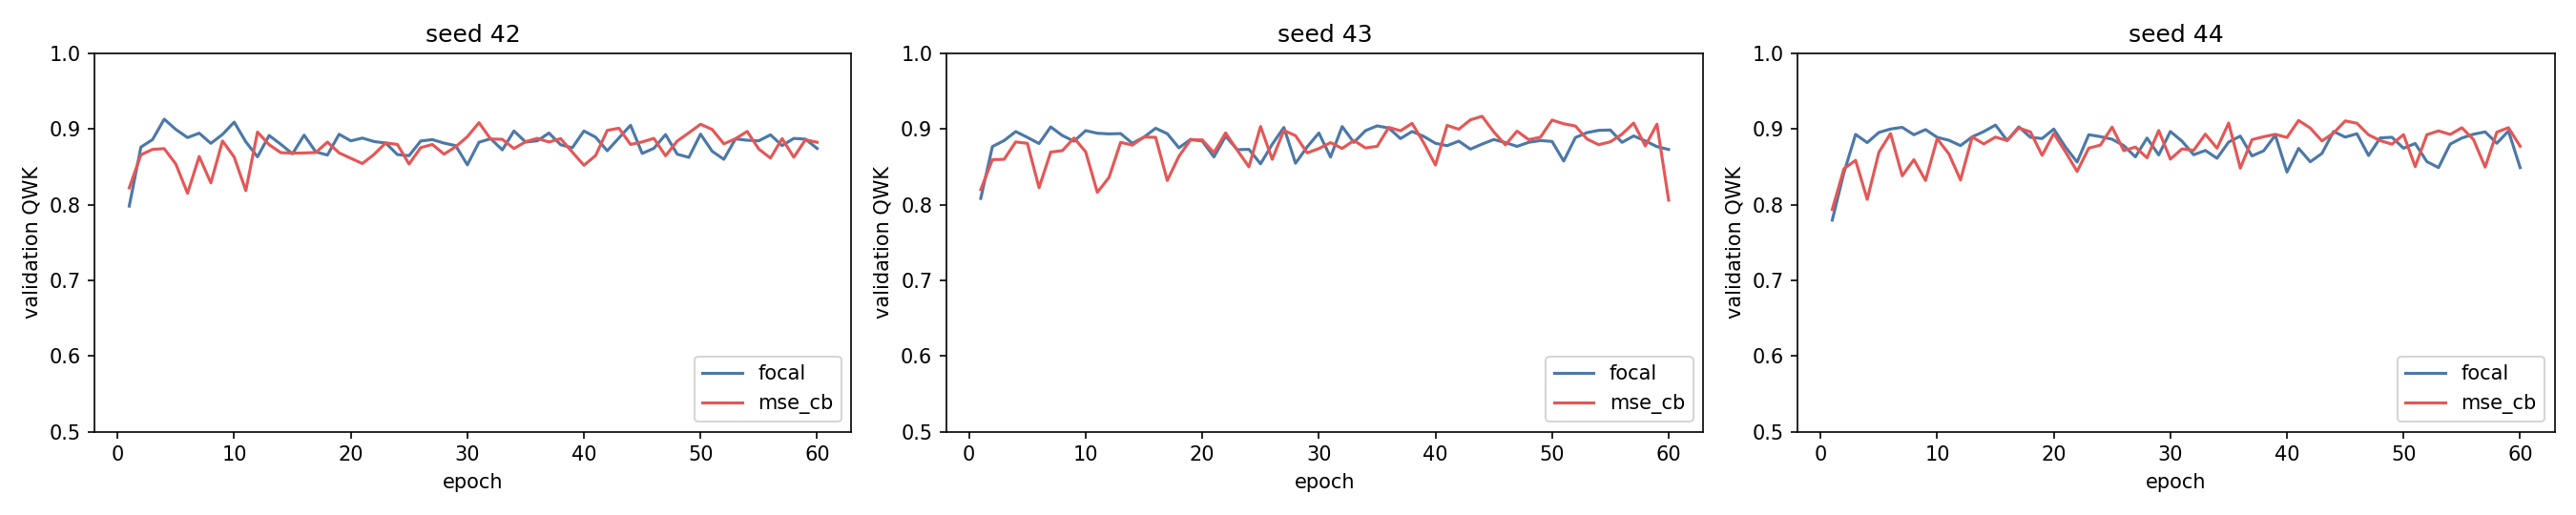

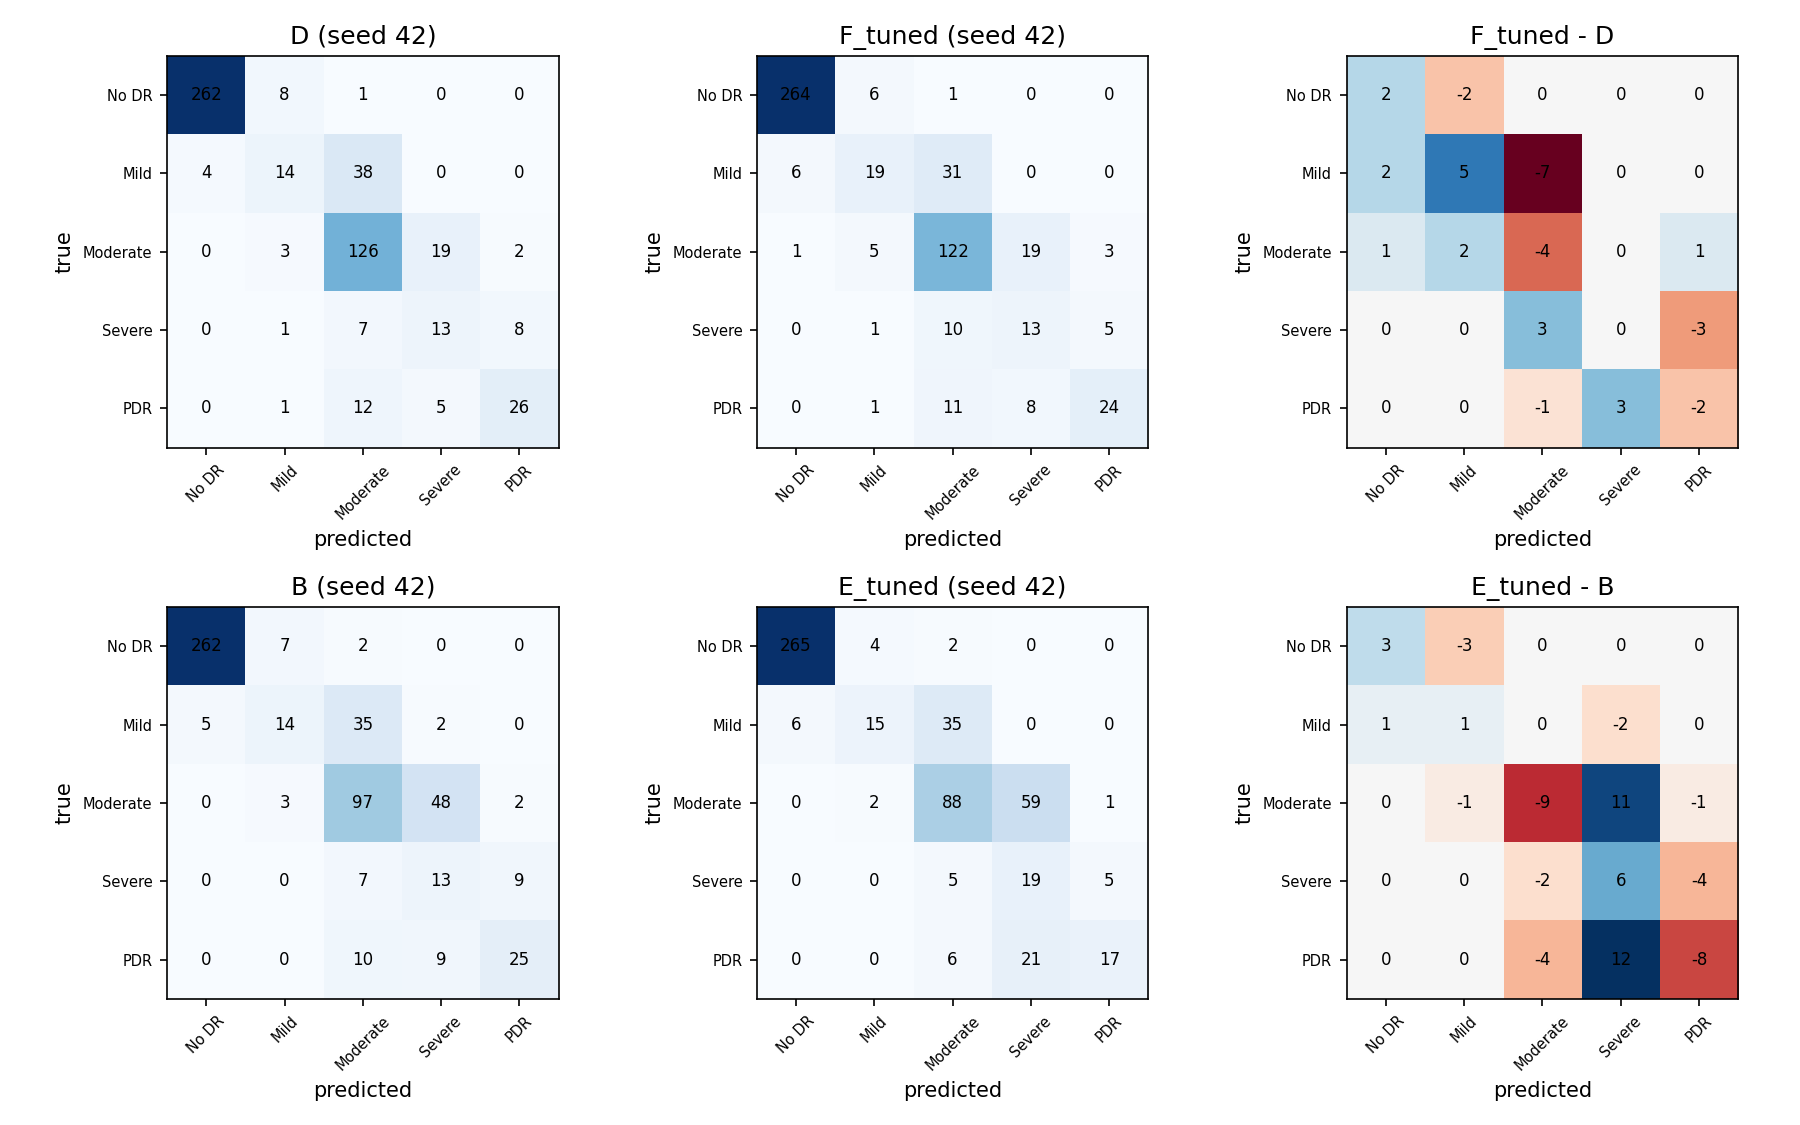

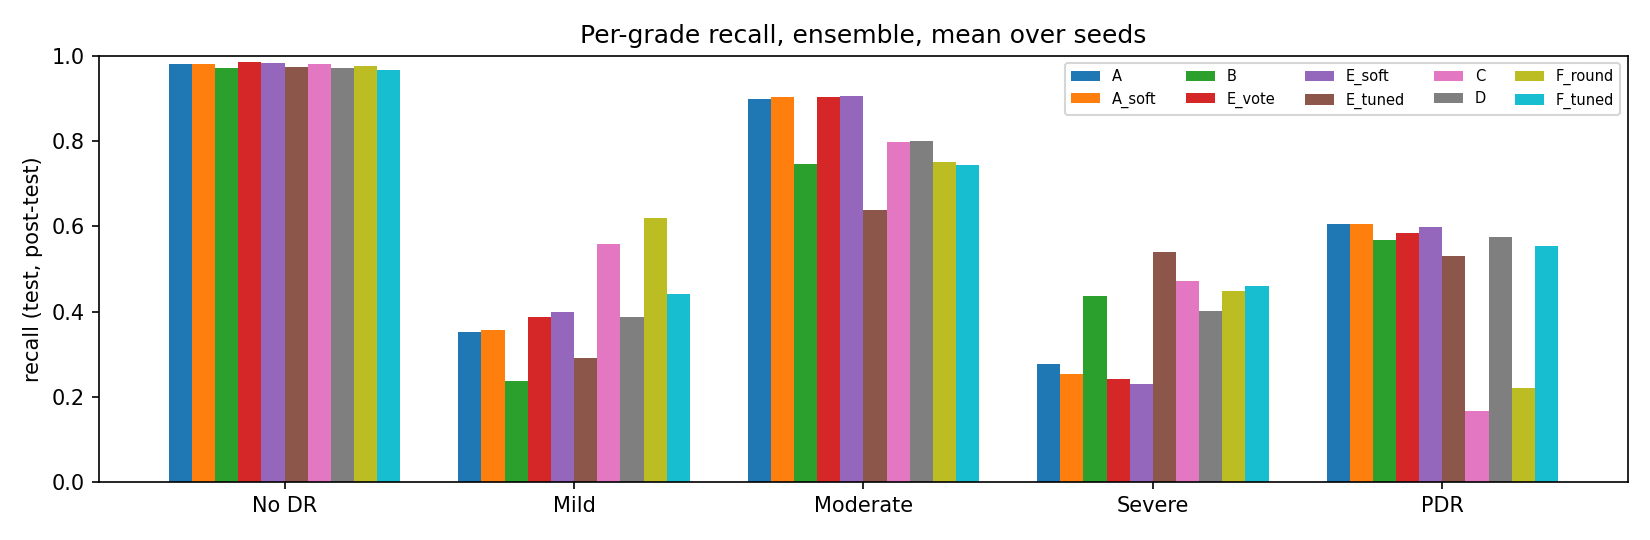

In [10]:
def plot_cm(ax, cm, title, diverging=False):
    cm = np.asarray(cm)
    vmax = np.abs(cm).max() or 1
    ax.imshow(cm, cmap="RdBu" if diverging else "Blues", vmin=-vmax if diverging else 0, vmax=vmax)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, fontsize=7)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=7)
    ax.set(title=title, xlabel="predicted", ylabel="true")


if ANALYSE:
    recall_cols = [f"recall_{c}" for c in CLASS_NAMES]
    present = [a for a in ARM_ORDER if a in set(ens["arm"])]
    rec = ens.groupby("arm")[recall_cols].mean().loc[present]
    fig, ax = plt.subplots(figsize=(11, 3.6))
    width = 0.8 / len(present)
    for k, arm in enumerate(present):
        ax.bar(np.arange(NUM_CLASSES) + k * width, rec.loc[arm], width, label=arm)
    ax.set_xticks(np.arange(NUM_CLASSES) + 0.4 - width / 2, CLASS_NAMES)
    ax.set(ylabel="recall (test, post-test)", ylim=(0, 1), title="Per-grade recall, ensemble, mean over seeds")
    ax.legend(ncol=5, fontsize=7)
    plt.tight_layout(); plt.savefig(FIG_DIR / "recall_per_grade.png", dpi=150); plt.show()

    seed0 = min(s for (g, s, mo, a) in decisions if g == "main" and a == "F_tuned") if any(
        a == "F_tuned" for (_, _, _, a) in decisions) else None
    pairs_cm = [("D", "F_tuned"), ("B", "E_tuned")]
    if seed0 is not None and all(("main", seed0, "ensemble", a) in decisions for p in pairs_cm for a in p):
        fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
        for row, (old, new) in enumerate(pairs_cm):
            cms = [confusion_matrix(*decisions[("main", seed0, "ensemble", a)], labels=list(range(NUM_CLASSES))) for a in (old, new)]
            plot_cm(axes[row, 0], cms[0], f"{old} (seed {seed0})")
            plot_cm(axes[row, 1], cms[1], f"{new} (seed {seed0})")
            plot_cm(axes[row, 2], cms[1] - cms[0], f"{new} - {old}", diverging=True)
        plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

    logged = {n: r for n, r in runs.items() if "log" in r}
    if logged:
        fig, axes = plt.subplots(1, len(SEEDS), figsize=(6 * len(SEEDS), 3.6), squeeze=False)
        for ax, seed in zip(axes[0], SEEDS):
            for loss, color in (("focal", "#4C78A8"), ("mse_cb", "#E45756")):
                if f"{loss}_s{seed}" in logged:
                    log = logged[f"{loss}_s{seed}"]["log"]
                    ax.plot(log["epoch"], log["val_qwk"], color=color, label=loss)
            ax.set(title=f"seed {seed}", xlabel="epoch", ylabel="validation QWK", ylim=(0.5, 1.0))
            ax.legend(loc="lower right")
        plt.tight_layout(); plt.savefig(FIG_DIR / "validation_curves.png", dpi=150); plt.show()

## 9. Stage 4 post-hoc checks that need the images (exploratory, not pre-registered)

These are carried over from Stage 4, section 12 (checks 3 and 4). They concern arm D, seed 42 (the Stage 4 `mse_s42` run).

1. **Image quality:** Mann-Whitney U tests of whether misgraded test images are blurrier (variance of the Laplacian) or darker (mean grey level inside the retina) than correctly graded ones.
2. **Grad-CAM inside the retina:** at 300 px, EfficientNet-B3's stride-2 convolutions pad only the top and left edges. The top-left feature cell is therefore always the strongest, and it lies on the black background. Feature cells that are mostly outside the retina are dropped before the map is scaled.

In [11]:
def quality(path):
    gray = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY)
    retina = gray > 10
    return cv2.Laplacian(gray, cv2.CV_64F).var(), float(gray[retina].mean()) if retina.any() else 0.0


if ANALYSE and ("main", 42, "ensemble", "D") in decisions:
    test_idx = SPLITS[False]["test"]
    y_test, pred_d = decisions[("main", 42, "ensemble", "D")]
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        sharpness, brightness = map(np.array, zip(*pool.map(quality, df["path"].to_numpy()[test_idx])))
    wrong = pred_d != y_test
    quality_rows = []
    for qname, values in (("sharpness", sharpness), ("brightness", brightness)):
        quality_rows.append({"measure": qname, "median correct": np.median(values[~wrong]),
                             "median misgraded": np.median(values[wrong]), "n correct": int((~wrong).sum()),
                             "n misgraded": int(wrong.sum()),
                             "mann_whitney_p": float(mannwhitneyu(values[wrong], values[~wrong]).pvalue)})
    quality_test = pd.DataFrame(quality_rows)
    quality_test.to_csv(STAGE4E_DIR / "posthoc_image_quality.csv", index=False)
    display(quality_test.round(4))

posthoc_image_quality.csv
   measure  median correct  median misgraded  n correct  n misgraded  mann_whitney_p
 sharpness       62.788774         50.936432        441          109        0.000489
brightness       92.923416         87.818343        441          109        0.045668

posthoc_gradcam_corner_share.csv
              kind  test_position   true     pred  top_left_share
     missed Severe            477 Severe Moderate        0.330170
     missed Severe            484 Severe Moderate        0.463681
     missed Severe            486 Severe Moderate        0.395332
     missed Severe            487 Severe Moderate        0.498075
       large error            508    PDR     Mild        0.544432
       large error            539    PDR     Mild        0.771989
correct Severe/PDR            479 Severe   Severe        0.268743
correct Severe/PDR            481 Severe   Severe        0.296556

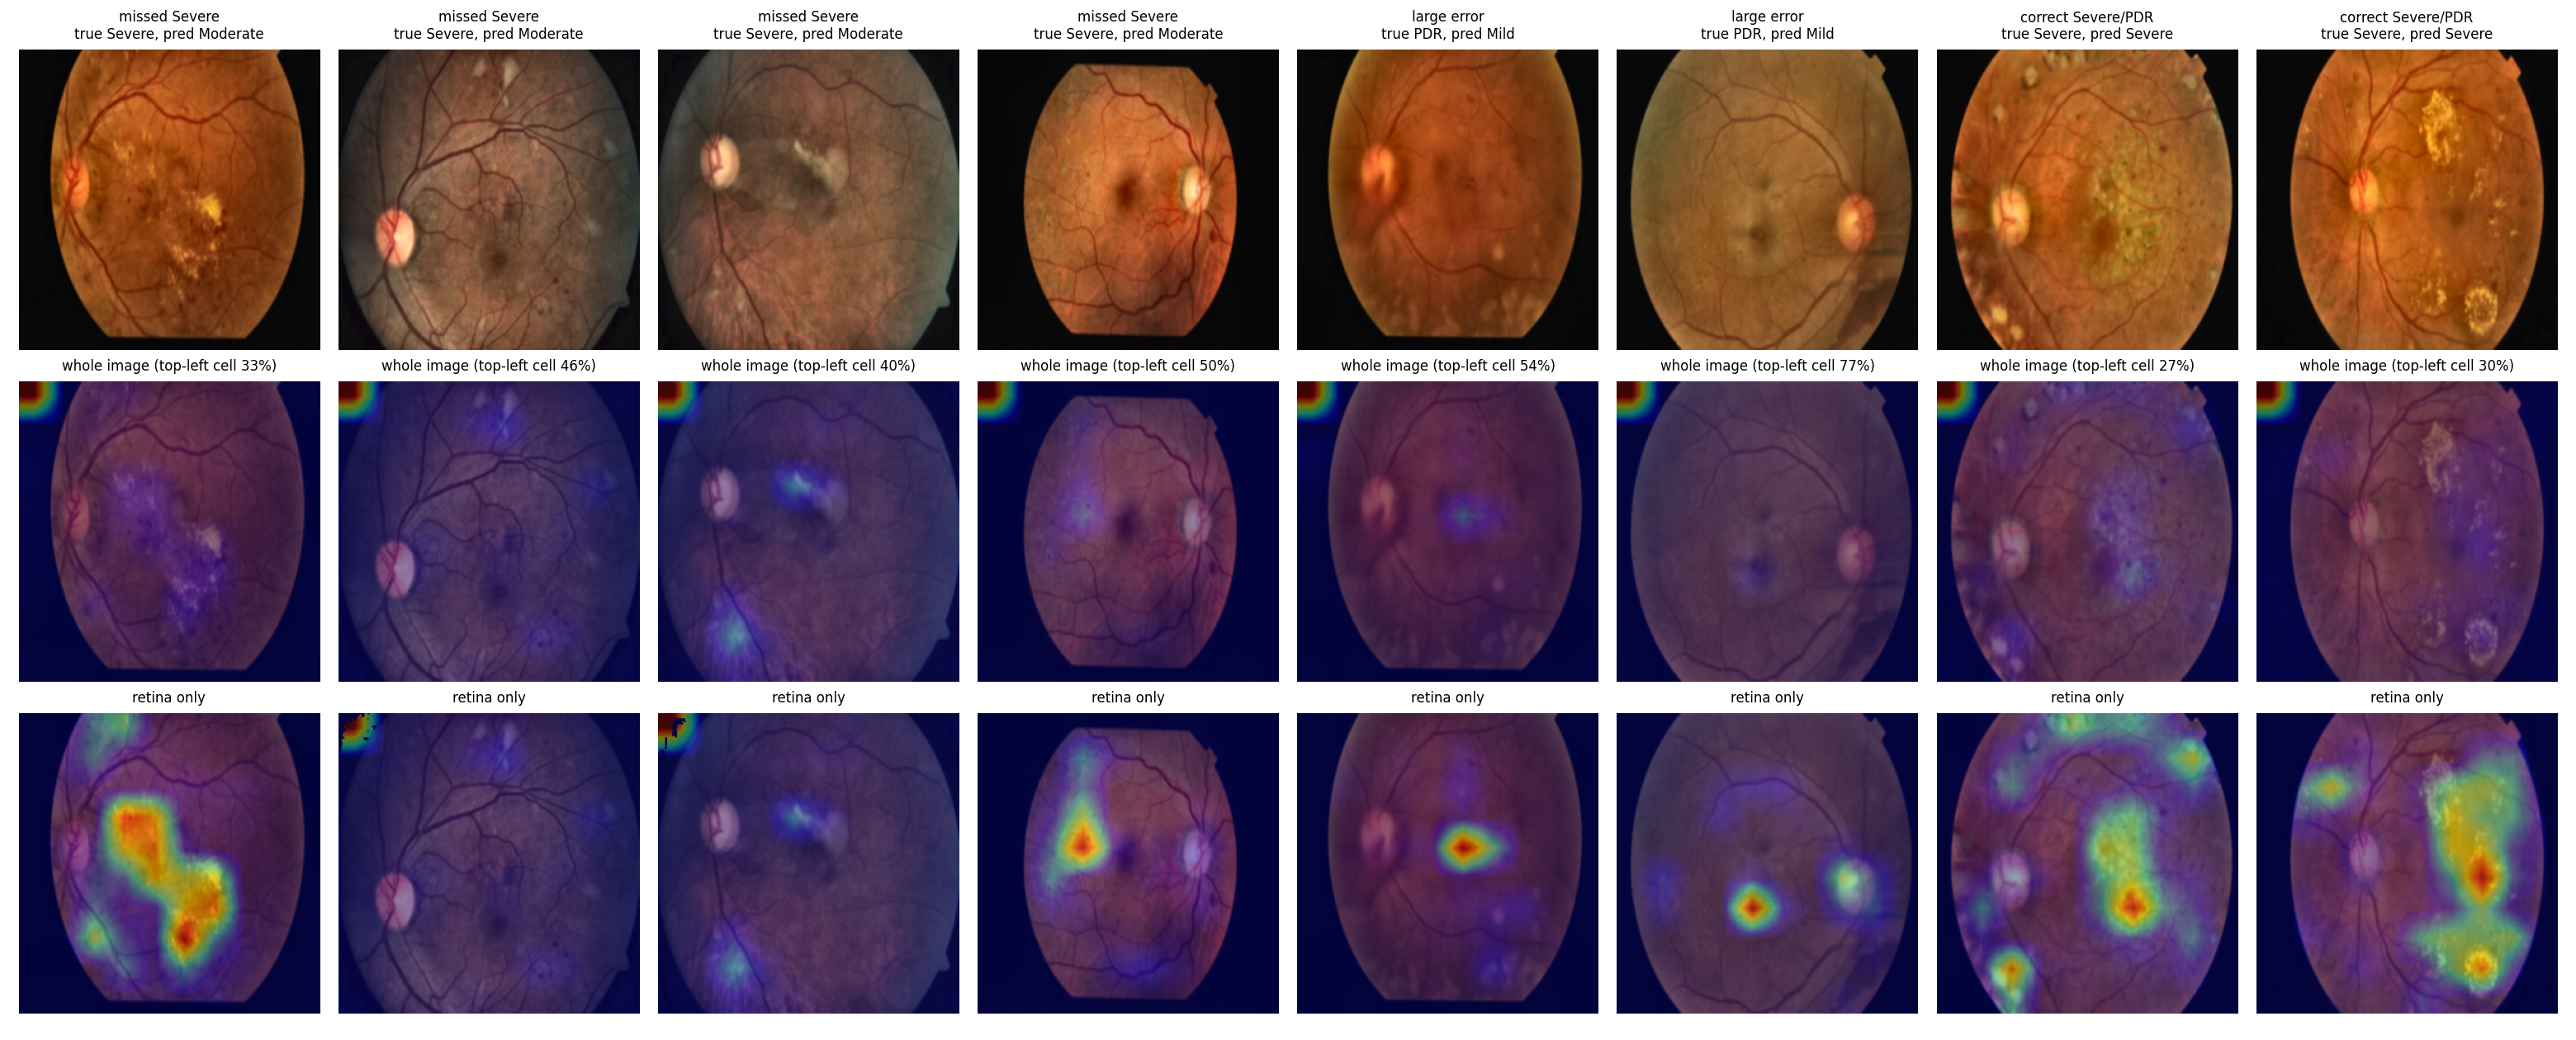

In [12]:
def grad_cam(model, image_uint8):
    # Grad-CAM on the last feature map (Stage 4, section 11). Target: the regression output or the predicted logit.
    model.eval()
    feats = model.backbone.forward_features(to_model_input(image_uint8[None]))
    feats.retain_grad()
    out = model.head(model.backbone.forward_head(feats))
    target = out[0, 0] if out.shape[1] == 1 else out[0, out[0].argmax()]
    model.zero_grad()
    target.backward()
    cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1))[0].detach().float().cpu().numpy()
    return cv2.resize(cam / (cam.max() + 1e-8), image_uint8.shape[1::-1])


def grad_cam_retina(model, image_uint8):
    # Stage 4, section 12: drop feature cells mostly outside the retina before scaling; also return the top-left
    # cell's share of the raw map.
    model.eval()
    feats = model.backbone.forward_features(to_model_input(image_uint8[None]))
    feats.retain_grad()
    out = model.head(model.backbone.forward_head(feats))
    target = out[0, 0] if out.shape[1] == 1 else out[0, out[0].argmax()]
    model.zero_grad()
    target.backward()
    cam = F.relu((feats.grad.mean((2, 3), keepdim=True) * feats).sum(1))[0].detach().float().cpu().numpy()
    corner_share = float(cam[0, 0] / (cam.sum() + 1e-8))
    retina = (cv2.cvtColor(image_uint8, cv2.COLOR_RGB2GRAY) > 10).astype(np.float32)
    inside = cv2.resize(retina, cam.shape[::-1], interpolation=cv2.INTER_AREA) >= 0.5
    cam = np.where(inside, cam, 0.0)
    cam = cv2.resize(cam / (cam.max() + 1e-8), image_uint8.shape[1::-1]) * retina
    return cam, corner_share


if ANALYSE and GRADCAM_WEIGHTS is not None and ("main", 42, "single", "D") in decisions:
    test_idx = SPLITS[False]["test"]
    cam_model = DRNet("efficientnet_b3", False, 1).to(device).to(memory_format=torch.channels_last)
    cam_model.load_state_dict(torch.load(GRADCAM_WEIGHTS, map_location=device))
    y_test, pred_single = decisions[("main", 42, "single", "D")]
    picks = ([("missed Severe", i) for i in np.flatnonzero((y_test == 3) & (pred_single < 3))[:4]]
             + [("large error", i) for i in np.argsort(-np.abs(pred_single - y_test))[:2] if pred_single[i] != y_test[i]]
             + [("correct Severe/PDR", i) for i in np.flatnonzero((y_test >= 3) & (pred_single == y_test))[:2]])
    shares = []
    fig, axes = plt.subplots(3, len(picks), figsize=(2.6 * len(picks), 8.4), squeeze=False)
    for col, (kind, i) in enumerate(picks):
        img = images[test_idx[i]]
        cam_raw = grad_cam(cam_model, img)
        cam_in, corner_share = grad_cam_retina(cam_model, img)
        shares.append({"kind": kind, "test_position": int(i), "true": CLASS_NAMES[y_test[i]],
                       "pred": CLASS_NAMES[pred_single[i]], "top_left_share": corner_share})
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"{kind}\ntrue {CLASS_NAMES[y_test[i]]}, pred {CLASS_NAMES[pred_single[i]]}", fontsize=8)
        axes[1, col].imshow(img); axes[1, col].imshow(cam_raw, cmap="jet", alpha=0.45)
        axes[1, col].set_title(f"whole image (top-left cell {corner_share:.0%})", fontsize=8)
        axes[2, col].imshow(img); axes[2, col].imshow(cam_in, cmap="jet", alpha=0.45)
        axes[2, col].set_title("retina only", fontsize=8)
        for ax in axes[:, col]:
            ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_retina.png", dpi=150); plt.show()
    pd.DataFrame(shares).to_csv(STAGE4E_DIR / "posthoc_gradcam_corner_share.csv", index=False)
elif ANALYSE:
    print("Grad-CAM skipped: no mse_s42 weights among the inputs")

## 10. Files

Written to `dr-grading/stage4e/` in the final kernel's output: `results_per_seed.csv`, `results_mean_over_seeds.csv`, `paired_bootstrap.csv`, `prediction_check.csv`, `control_check.csv`, `cutoffs.json`, `posthoc_image_quality.csv`, `posthoc_gradcam_corner_share.csv`, and `figures/{recall_per_grade, confusion_matrices, validation_curves, gradcam_retina}.png`. Each run's `runs/<name>/{config.json, log.csv, outputs.npz, results.json}` is also written. Download them with `kaggle kernels output <user>/dr-s4e-e2-final -p out` and commit them, without the `.pt` files, to `experiments/06_imbalance_losses/results/`.